# Experiments and failure analysis
Actual loading, decoding and checkpoint evidence. Full nine-adapter validation results are not available yet; this notebook does not invent them or rescore any holdout.

In [1]:
from pathlib import Path
import json,hashlib,collections
import numpy as np
import matplotlib.pyplot as plt
from IPython.display import display,HTML
ROOT=Path.cwd()
if not (ROOT/'src').exists(): ROOT=ROOT.parent
assert (ROOT/'src').exists()
import os
os.chdir(ROOT)
def read(path):return json.loads(Path(path).read_text(encoding='utf-8'))
def table(rows,title):
    if not rows:return
    columns=list(rows[0]);html='<h4>'+title+'</h4><table><tr>'+''.join('<th>'+c+'</th>' for c in columns)+'</tr>'
    for row in rows:html+='<tr>'+''.join('<td>'+str(row[c])+'</td>' for c in columns)+'</tr>'
    display(HTML(html+'</table>'))
def save_plot(name):
    plt.tight_layout();Path('docs/figures').mkdir(exist_ok=True)
    plt.savefig('docs/figures/'+name+'.png',dpi=150)
    plt.show()
SOURCE=Path('data/processed/didemo-v2')
CACHE=Path('data/interim/cloud-smoke-output-v1/video-smoke')
RUN_ENCODER=False
RUN_TRAINING=False
RUN_TEST=False


split,inspected,geometry_valid
train,365,364
val,73,73
test,47,47


Rejected source: One train video declared six bins but actual duration24.17 seconds; sixth bin has no real frames.
Policy: Exclude whole inconsistent source before outcomes; no padding, target remapping or scored replacement.


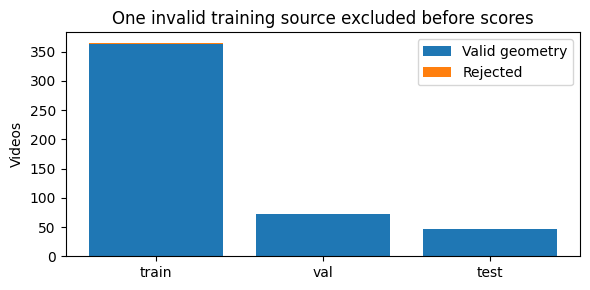

In [2]:
decoder=read('docs/decoder-preflight.json')
table([{'split':s,**r} for s,r in decoder['all_media_inspected'].items()],'All-source decoder preflight')
print('Rejected source:',decoder['failure'])
print('Policy:',decoder['policy'])
fig,ax=plt.subplots(figsize=(6,3));rows=decoder['all_media_inspected'];names=list(rows)
ax.bar(names,[rows[s]['geometry_valid'] for s in names],label='Valid geometry')
ax.bar(names,[rows[s]['inspected']-rows[s]['geometry_valid'] for s in names],bottom=[rows[s]['geometry_valid'] for s in names],label='Rejected')
ax.set(ylabel='Videos',title='One invalid training source excluded before scores');ax.legend();save_plot('decoder-audit')


In [3]:
receipt=read('docs/video-smoke.json')
table([{'check':k,'value':v} for k,v in receipt['encoder']['loading_info'].items()],'Actual pretrained loading diagnostics')
table([{'check':'Encoder cache replay','maximum absolute difference':receipt['feature_replay_max_abs_error']},
       {'check':'Adapter checkpoint replay','maximum absolute difference':receipt['adapter_training']['checkpoint_replay_max_abs_error']}],'Actual remote save/reload checks')


check,value
missing_keys,[]
unexpected_keys,[]
mismatched_keys,[]
error_msgs,[]


check,maximum absolute difference
Encoder cache replay,2.9802322387695312e-08
Adapter checkpoint replay,0.0


## Completed full-run analysis
Set FULL_RUN only to a downloaded, hash-verified output directory. Inspect every validation configuration and seed, not a favorable example. A different candidate corpus cannot be compared as if only model weights changed.

In [4]:
FULL_RUN=Path('data/interim/full-adapter-results-pending')
if not FULL_RUN.exists():
    print('Full CPU study pending: no training curves, validation winner or test score claimed.')
else:
    print('Completed directory found. Verify its hashes and protocol before adding aggregate analysis.')


Full CPU study pending: no training curves, validation winner or test score claimed.


## Failure categories
Decoder geometry can invalidate a source before scoring. Human references can have no consensus-positive candidate. Frozen CLIP can miss temporal order or small actions; averaged frames may erase brief events. Adapter improvements on available footage would not establish full-benchmark or unseen-domain performance. Exact hashes verify replay consistency, not semantic correctness.